In [4]:
from google.colab import drive
drive.mount('/content/drive')

import torch, numpy as np, pandas as pd
from datasets import Dataset

DATA = "/content/drive/MyDrive/mfasha"
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True Tesla T4


In [7]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive/Mfasha chatbot"):
    if "passages.jsonl" in files:
        print("FOUND:", root)
        print(files)

FOUND: /content/drive/MyDrive/Mfasha chatbot/data
['passages.jsonl', 'queries.jsonl', 'triplets_train.csv', 'pairs_train.csv', 'triplets_dev.csv', 'pairs_dev.csv', 'triplets_test.csv', 'pairs_test.csv']


In [8]:
import numpy as np, pandas as pd, torch
from datasets import Dataset

DATA = "/content/drive/MyDrive/Mfasha chatbot/data"

passages = pd.read_json(open(f"{DATA}/passages.jsonl", encoding="utf-8"), lines=True, dtype=False).astype(str)
queries  = pd.read_json(open(f"{DATA}/queries.jsonl",  encoding="utf-8"), lines=True, dtype=False).astype(str)

pid2text = dict(zip(passages.pid, passages.text))
qid2text = dict(zip(queries.qid, queries.text))
passage_texts = passages.text.tolist()
pid2idx = {p: i for i, p in enumerate(passages.pid)}

trip = pd.read_csv(f"{DATA}/triplets_train.csv", dtype=str)
trip = trip[trip.qid.isin(qid2text) & trip.pos_pid.isin(pid2text) & trip.neg_pid.isin(pid2text)]

# one random wrong passage per question
train = trip.groupby("qid").sample(1, random_state=42).reset_index(drop=True)

train_ds = Dataset.from_dict({
    "anchor":   train.qid.map(qid2text).tolist(),
    "positive": train.pos_pid.map(pid2text).tolist(),
    "negative": train.neg_pid.map(pid2text).tolist(),
})
print("training examples:", len(train_ds))
print("GPU:", torch.cuda.get_device_name(0))

training examples: 19012
GPU: Tesla T4


In [9]:
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers

BASE_MODEL = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
OUT_DIR = f"{DATA}/kinya-retriever"
EPOCHS, BATCH, LR, SEED = 1, 32, 2e-5, 42

model = SentenceTransformer(BASE_MODEL, device="cuda")
model.max_seq_length = 256

args = SentenceTransformerTrainingArguments(
    output_dir="/content/trainer_tmp",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH,
    learning_rate=LR,
    warmup_ratio=0.1,
    fp16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    save_strategy="no",
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = SentenceTransformerTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    loss=MultipleNegativesRankingLoss(model),
)
trainer.train()

model.save(OUT_DIR)
print("Saved to", OUT_DIR)

/tmp/ipykernel_4552/2319812440.py:2: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers.losses import MultipleNegativesRankingLoss
/tmp/ipykernel_4552/2319812440.py:3: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,2.610915
100,0.755225
150,0.524183
200,0.407939
250,0.350422
300,0.274738
350,0.223771
400,0.270233
450,0.193356
500,0.212299


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/Mfasha chatbot/data/kinya-retriever


In [10]:
import numpy as np, pandas as pd

pairs_dev = pd.read_csv(f"{DATA}/pairs_dev.csv", dtype=str)
dev_q = pairs_dev.qid.map(qid2text).tolist()
gold = np.array([pid2idx[p] for p in pairs_dev.pos_pid])

P = model.encode(passage_texts, batch_size=64, normalize_embeddings=True)
Q = model.encode(dev_q, batch_size=64, normalize_embeddings=True)
S = Q @ P.T
r = (S >= S[np.arange(len(S)), gold][:, None]).sum(1)

finetuned = {
    "Recall@1":  (r <= 1).mean(),
    "Recall@5":  (r <= 5).mean(),
    "Recall@10": (r <= 10).mean(),
    "MRR@10":    np.where(r <= 10, 1 / r, 0).mean(),
}

table = pd.DataFrame({
    "BM25":                    {"Recall@1": 0.520, "Recall@5": 0.776, "Recall@10": 0.857, "MRR@10": 0.627},
    "Base embeddings (mpnet)": {"Recall@1": 0.102, "Recall@5": 0.143, "Recall@10": 0.148, "MRR@10": 0.115},
    "Fine-tuned (1 epoch)":    finetuned,
}).T

print(table.round(3).to_string())
table.round(4).to_csv(f"{DATA}/retriever_dev_e1.csv")

                         Recall@1  Recall@5  Recall@10  MRR@10
BM25                        0.520     0.776      0.857   0.627
Base embeddings (mpnet)     0.102     0.143      0.148   0.115
Fine-tuned (1 epoch)        0.633     0.852      0.929   0.729


In [ ]:
import gc, torch, numpy as np, pandas as pd
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers

EPOCHS = 2                                    
OUT_DIR = f"{DATA}/kinya-retriever-e{EPOCHS}"

# free the GPU memory from the previous model
try:
    del model, trainer
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

# train from the BASE model again
model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", device="cuda")
model.max_seq_length = 256

args = SentenceTransformerTrainingArguments(
    output_dir="/content/trainer_tmp",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    fp16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    save_strategy="no",
    logging_steps=100,
    report_to="none",
    seed=42,
)
trainer = SentenceTransformerTrainer(
    model=model, args=args, train_dataset=train_ds,
    loss=MultipleNegativesRankingLoss(model),
)
trainer.train()
model.save(OUT_DIR)
print("Saved to", OUT_DIR)

# evaluate on dev
pairs_dev = pd.read_csv(f"{DATA}/pairs_dev.csv", dtype=str)
dev_q = pairs_dev.qid.map(qid2text).tolist()
gold = np.array([pid2idx[p] for p in pairs_dev.pos_pid])

P = model.encode(passage_texts, batch_size=64, normalize_embeddings=True)
Q = model.encode(dev_q, batch_size=64, normalize_embeddings=True)
S = Q @ P.T
r = (S >= S[np.arange(len(S)), gold][:, None]).sum(1)

res = {
    "Recall@1":  (r <= 1).mean(),
    "Recall@5":  (r <= 5).mean(),
    "Recall@10": (r <= 10).mean(),
    "MRR@10":    np.where(r <= 10, 1 / r, 0).mean(),
}

table = pd.DataFrame({
    "BM25":                  {"Recall@1": 0.520, "Recall@5": 0.776, "Recall@10": 0.857, "MRR@10": 0.627},
    "Fine-tuned (1 epoch)":  {"Recall@1": 0.633, "Recall@5": 0.852, "Recall@10": 0.929, "MRR@10": 0.729},
    f"Fine-tuned ({EPOCHS} epochs)": res,
}).T
print(table.round(3).to_string())
table.round(4).to_csv(f"{DATA}/retriever_dev_e{EPOCHS}.csv")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
100,2.060033
200,0.535158
300,0.331195
400,0.257643
500,0.205823
600,0.192400
700,0.113489
800,0.122091
900,0.117469
1000,0.102765


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/Mfasha chatbot/data/kinya-retriever-e2
                       Recall@1  Recall@5  Recall@10  MRR@10
BM25                      0.520     0.776      0.857   0.627
Fine-tuned (1 epoch)      0.633     0.852      0.929   0.729
Fine-tuned (2 epochs)     0.668     0.862      0.949   0.754


In [12]:
import gc, torch, numpy as np, pandas as pd
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers

EPOCHS = 5
OUT_DIR = f"{DATA}/kinya-retriever-e{EPOCHS}"

# free the GPU memory from the previous model
try:
    del model, trainer
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

# train from the BASE model again
model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", device="cuda")
model.max_seq_length = 256

args = SentenceTransformerTrainingArguments(
    output_dir="/content/trainer_tmp",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    fp16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    save_strategy="no",
    logging_steps=100,
    report_to="none",
    seed=42,
)
trainer = SentenceTransformerTrainer(
    model=model, args=args, train_dataset=train_ds,
    loss=MultipleNegativesRankingLoss(model),
)
trainer.train()
model.save(OUT_DIR)
print("Saved to", OUT_DIR)

# evaluate on dev
pairs_dev = pd.read_csv(f"{DATA}/pairs_dev.csv", dtype=str)
dev_q = pairs_dev.qid.map(qid2text).tolist()
gold = np.array([pid2idx[p] for p in pairs_dev.pos_pid])

P = model.encode(passage_texts, batch_size=64, normalize_embeddings=True)
Q = model.encode(dev_q, batch_size=64, normalize_embeddings=True)
S = Q @ P.T
r = (S >= S[np.arange(len(S)), gold][:, None]).sum(1)

res = {
    "Recall@1":  (r <= 1).mean(),
    "Recall@5":  (r <= 5).mean(),
    "Recall@10": (r <= 10).mean(),
    "MRR@10":    np.where(r <= 10, 1 / r, 0).mean(),
}

table = pd.DataFrame({
    "BM25":                  {"Recall@1": 0.520, "Recall@5": 0.776, "Recall@10": 0.857, "MRR@10": 0.627},
    "Fine-tuned (1 epoch)":  {"Recall@1": 0.633, "Recall@5": 0.852, "Recall@10": 0.929, "MRR@10": 0.729},
    "Fine-tuned (2 epochs)": {"Recall@1": 0.668, "Recall@5": 0.862, "Recall@10": 0.949, "MRR@10": 0.754},
    f"Fine-tuned ({EPOCHS} epochs)": res,
}).T
print(table.round(3).to_string())
table.round(4).to_csv(f"{DATA}/retriever_dev_e{EPOCHS}.csv")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
100,2.657075
200,0.836309
300,0.442307
400,0.308064
500,0.240322
600,0.217842
700,0.138255
800,0.141495
900,0.132131
1000,0.122764


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/Mfasha chatbot/data/kinya-retriever-e5
                       Recall@1  Recall@5  Recall@10  MRR@10
BM25                      0.520     0.776      0.857   0.627
Fine-tuned (1 epoch)      0.633     0.852      0.929   0.729
Fine-tuned (2 epochs)     0.668     0.862      0.949   0.754
Fine-tuned (5 epochs)     0.735     0.918      0.939   0.809


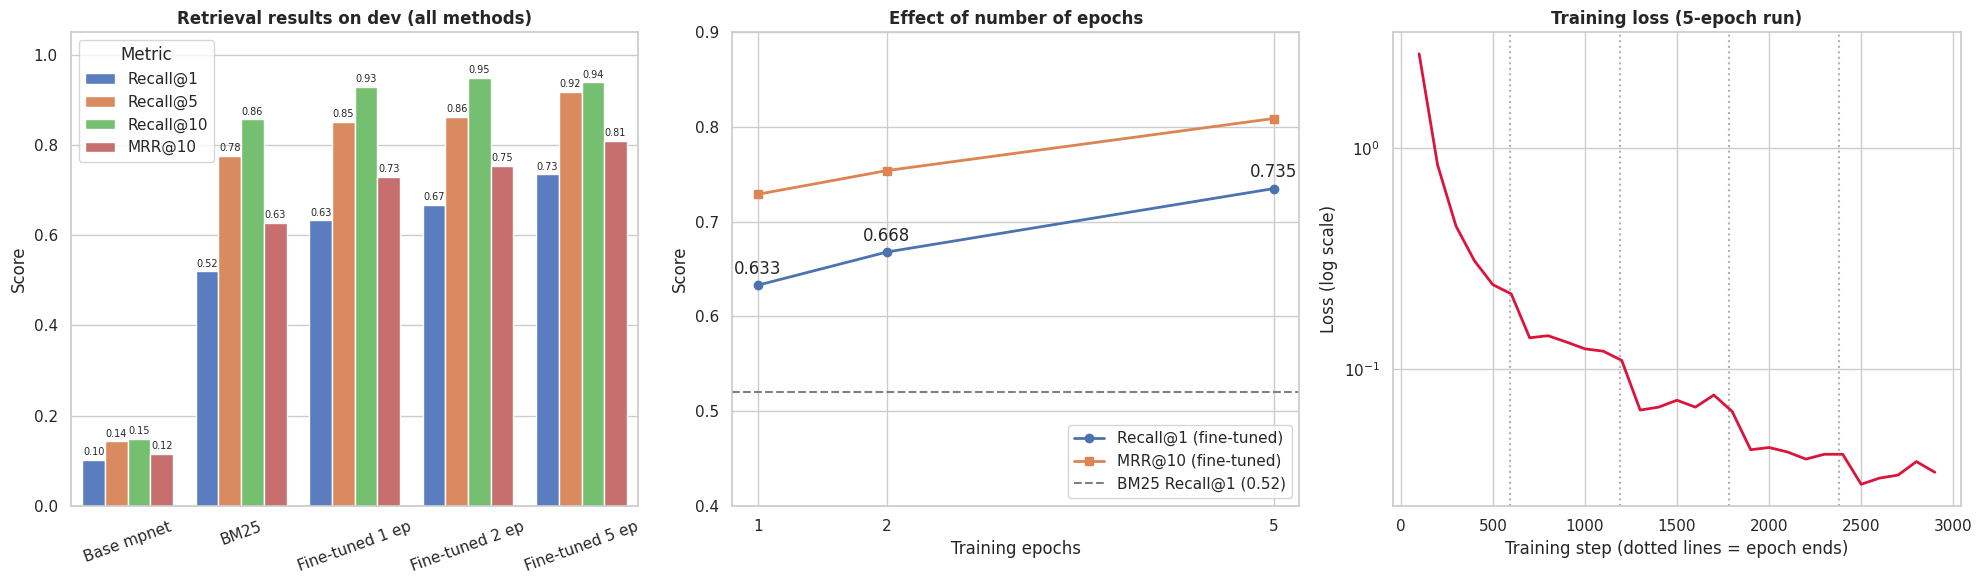

Saved: /content/drive/MyDrive/Mfasha chatbot/data/finetuning_results.png


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

# Where to save: laptop -> RESULTS_DIR, Colab -> your Drive data folder
try:
    SAVE_DIR = RESULTS_DIR
except NameError:
    SAVE_DIR = Path(DATA)
SAVE_DIR = Path(SAVE_DIR)

sns.set_theme(style="whitegrid")

# Your dev results
res = pd.DataFrame({
    "Base mpnet":      {"Recall@1": 0.102, "Recall@5": 0.143, "Recall@10": 0.148, "MRR@10": 0.115},
    "BM25":            {"Recall@1": 0.520, "Recall@5": 0.776, "Recall@10": 0.857, "MRR@10": 0.627},
    "Fine-tuned 1 ep": {"Recall@1": 0.633, "Recall@5": 0.852, "Recall@10": 0.929, "MRR@10": 0.729},
    "Fine-tuned 2 ep": {"Recall@1": 0.668, "Recall@5": 0.862, "Recall@10": 0.949, "MRR@10": 0.754},
    "Fine-tuned 5 ep": {"Recall@1": 0.735, "Recall@5": 0.918, "Recall@10": 0.939, "MRR@10": 0.809},
}).T

# Training loss of the 5-epoch run (from your log)
steps = list(range(100, 3000, 100))
loss5 = [2.657, 0.836, 0.442, 0.308, 0.240, 0.218, 0.138, 0.141, 0.132, 0.123,
         0.120, 0.109, 0.065, 0.067, 0.072, 0.067, 0.076, 0.064, 0.043, 0.044,
         0.042, 0.039, 0.041, 0.041, 0.030, 0.032, 0.033, 0.038, 0.034]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: all methods, all metrics
melted = res.reset_index().melt(id_vars="index", var_name="Metric", value_name="Score")
sns.barplot(data=melted, x="index", y="Score", hue="Metric", palette="muted", ax=axes[0])
axes[0].set_title("Retrieval results on dev (all methods)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=20)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7, padding=2)

# Plot 2: Recall@1 and MRR vs epochs, with BM25 as a reference line
epochs = [1, 2, 5]
r1  = [res.loc[f"Fine-tuned {e} ep", "Recall@1"] for e in epochs]
mrr = [res.loc[f"Fine-tuned {e} ep", "MRR@10"]   for e in epochs]
axes[1].plot(epochs, r1,  marker="o", linewidth=2, label="Recall@1 (fine-tuned)")
axes[1].plot(epochs, mrr, marker="s", linewidth=2, label="MRR@10 (fine-tuned)")
axes[1].axhline(res.loc["BM25", "Recall@1"], color="gray", linestyle="--", label="BM25 Recall@1 (0.52)")
for x, y in zip(epochs, r1):
    axes[1].annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
axes[1].set_xticks(epochs)
axes[1].set_title("Effect of number of epochs", fontweight="bold")
axes[1].set_xlabel("Training epochs")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.4, 0.9)
axes[1].legend(loc="lower right")

# Plot 3: training loss curve (5 epochs)
axes[2].plot(steps, loss5, color="crimson", linewidth=2)
for ep_end in (595, 1190, 1785, 2380):
    axes[2].axvline(ep_end, color="gray", linestyle=":", alpha=0.6)
axes[2].set_yscale("log")
axes[2].set_title("Training loss (5-epoch run)", fontweight="bold")
axes[2].set_xlabel("Training step (dotted lines = epoch ends)")
axes[2].set_ylabel("Loss (log scale)")

plt.tight_layout()
out = SAVE_DIR / "finetuning_results.png"
plt.savefig(out, dpi=300)
plt.show()
print("Saved:", out)

In [14]:
!pip install -q rank_bm25 sentence-transformers

import re, numpy as np, pandas as pd
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

DATA = "/content/drive/MyDrive/Mfasha chatbot/data"

passages = pd.read_json(open(f"{DATA}/passages.jsonl", encoding="utf-8"), lines=True, dtype=False).astype(str)
queries  = pd.read_json(open(f"{DATA}/queries.jsonl",  encoding="utf-8"), lines=True, dtype=False).astype(str)
qid2text = dict(zip(queries.qid, queries.text))
passage_texts = passages.text.tolist()
pid2idx = {p: i for i, p in enumerate(passages.pid)}

pairs_dev = pd.read_csv(f"{DATA}/pairs_dev.csv", dtype=str)
dev_q = pairs_dev.qid.map(qid2text).tolist()
gold  = np.array([pid2idx[p] for p in pairs_dev.pos_pid])

# fine-tuned 5-epoch model
model = SentenceTransformer(f"{DATA}/kinya-retriever-e5", device="cuda")
model.max_seq_length = 256
P = model.encode(passage_texts, batch_size=64, normalize_embeddings=True)
Q = model.encode(dev_q, batch_size=64, normalize_embeddings=True)
S_emb = Q @ P.T

# BM25
tok = lambda t: re.findall(r"\w+", t.lower())
bm25 = BM25Okapi([tok(t) for t in passage_texts])
S_bm25 = np.vstack([bm25.get_scores(tok(q)) for q in dev_q])
print("ready:", S_emb.shape, S_bm25.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ready: (196, 984) (196, 984)


In [15]:
def to_rank(S):
    return np.argsort(np.argsort(-S, axis=1), axis=1) + 1

def rrf(mats, weights, k=60):
    return sum(w / (k + to_rank(S)) for S, w in zip(mats, weights))

def minmax(S):
    mn, mx = S.min(1, keepdims=True), S.max(1, keepdims=True)
    return (S - mn) / (mx - mn + 1e-9)

def score_mix(w_emb):
    return w_emb * minmax(S_emb) + (1 - w_emb) * minmax(S_bm25)

def evaluate(S, name):
    g = S[np.arange(len(S)), gold][:, None]
    r = (S >= g).sum(1)
    return {"method": name,
            "Recall@1": (r <= 1).mean(), "Recall@5": (r <= 5).mean(),
            "Recall@10": (r <= 10).mean(),
            "MRR@10": np.where(r <= 10, 1 / r, 0).mean()}

rows = [evaluate(S_bm25, "BM25"), evaluate(S_emb, "Fine-tuned (5 ep)")]
for w in (1, 2, 4):
    rows.append(evaluate(rrf([S_bm25, S_emb], [1.0, float(w)]), f"RRF  BM25:emb = 1:{w}"))
for w in (0.5, 0.6, 0.7, 0.8, 0.9):
    rows.append(evaluate(score_mix(w), f"Score mix  emb weight {w}"))

results = pd.DataFrame(rows).set_index("method")
print(results.round(3).to_string())
results.round(4).to_csv(f"{DATA}/hybrid_dev.csv")

                           Recall@1  Recall@5  Recall@10  MRR@10
method                                                          
BM25                          0.520     0.776      0.857   0.627
Fine-tuned (5 ep)             0.735     0.918      0.939   0.809
RRF  BM25:emb = 1:1           0.694     0.857      0.883   0.763
RRF  BM25:emb = 1:2           0.781     0.867      0.923   0.824
RRF  BM25:emb = 1:4           0.770     0.903      0.934   0.828
Score mix  emb weight 0.5     0.699     0.852      0.918   0.772
Score mix  emb weight 0.6     0.760     0.888      0.939   0.814
Score mix  emb weight 0.7     0.760     0.913      0.944   0.821
Score mix  emb weight 0.8     0.760     0.913      0.949   0.829
Score mix  emb weight 0.9     0.765     0.923      0.939   0.830


In [16]:
import numpy as np, pandas as pd, re
from sentence_transformers import SentenceTransformer

W_EMB = 0.8   # final choice, fixed from dev

pairs_test = pd.read_csv(f"{DATA}/pairs_test.csv", dtype=str)
test_q = pairs_test.qid.map(qid2text).tolist()
gold_t = np.array([pid2idx[p] for p in pairs_test.pos_pid])

def minmax(S):
    mn, mx = S.min(1, keepdims=True), S.max(1, keepdims=True)
    return (S - mn) / (mx - mn + 1e-9)

def evaluate_t(S, name):
    g = S[np.arange(len(S)), gold_t][:, None]
    r = (S >= g).sum(1)
    return {"method": name,
            "Recall@1": (r <= 1).mean(), "Recall@5": (r <= 5).mean(),
            "Recall@10": (r <= 10).mean(),
            "MRR@10": np.where(r <= 10, 1 / r, 0).mean()}

# BM25
tok = lambda t: re.findall(r"\w+", t.lower())
S_bm25_t = np.vstack([bm25.get_scores(tok(q)) for q in test_q])

# fine-tuned model (already loaded, passage embeddings P already computed)
Qt = model.encode(test_q, batch_size=64, normalize_embeddings=True)
S_emb_t = Qt @ P.T

# base model
base = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", device="cuda")
base.max_seq_length = 256
Pb = base.encode(passage_texts, batch_size=64, normalize_embeddings=True)
S_base_t = base.encode(test_q, batch_size=64, normalize_embeddings=True) @ Pb.T

S_hybrid_t = W_EMB * minmax(S_emb_t) + (1 - W_EMB) * minmax(S_bm25_t)

final = pd.DataFrame([
    evaluate_t(S_base_t,   "Base mpnet"),
    evaluate_t(S_bm25_t,   "BM25"),
    evaluate_t(S_emb_t,    "Fine-tuned (5 ep)"),
    evaluate_t(S_hybrid_t, f"Hybrid (score mix, emb {W_EMB})"),
]).set_index("method")

print("FINAL RESULTS ON TEST")
print(final.round(3).to_string())
final.round(4).to_csv(f"{DATA}/final_test_results.csv")

np.save(f"{DATA}/passage_emb_e5.npy", P)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

FINAL RESULTS ON TEST
                             Recall@1  Recall@5  Recall@10  MRR@10
method                                                            
Base mpnet                      0.036     0.097      0.140   0.063
BM25                            0.486     0.723      0.799   0.594
Fine-tuned (5 ep)               0.562     0.796      0.848   0.667
Hybrid (score mix, emb 0.8)     0.608     0.891      0.948   0.731


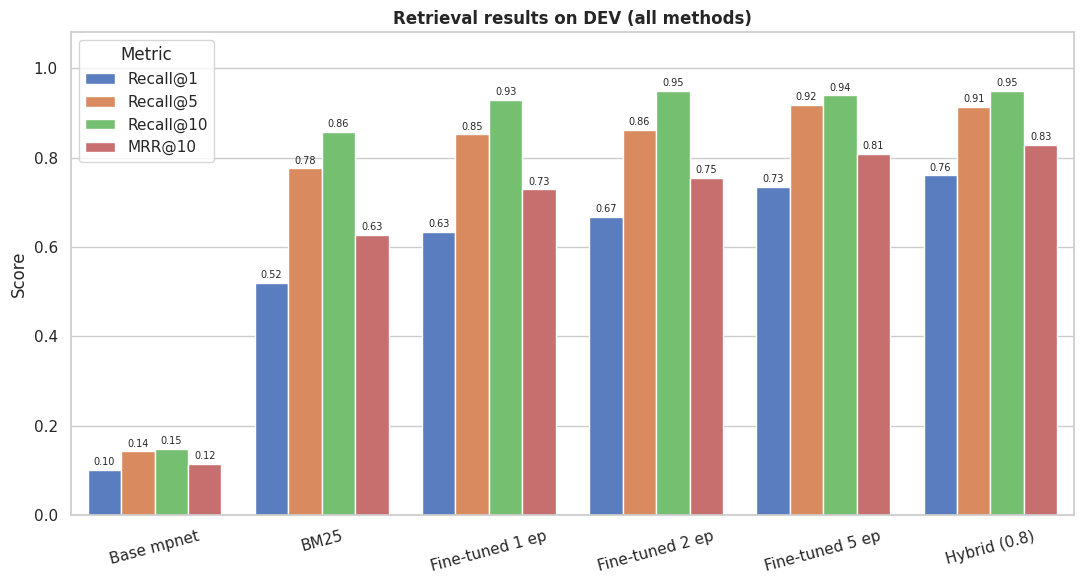

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g1_dev_all_methods.png


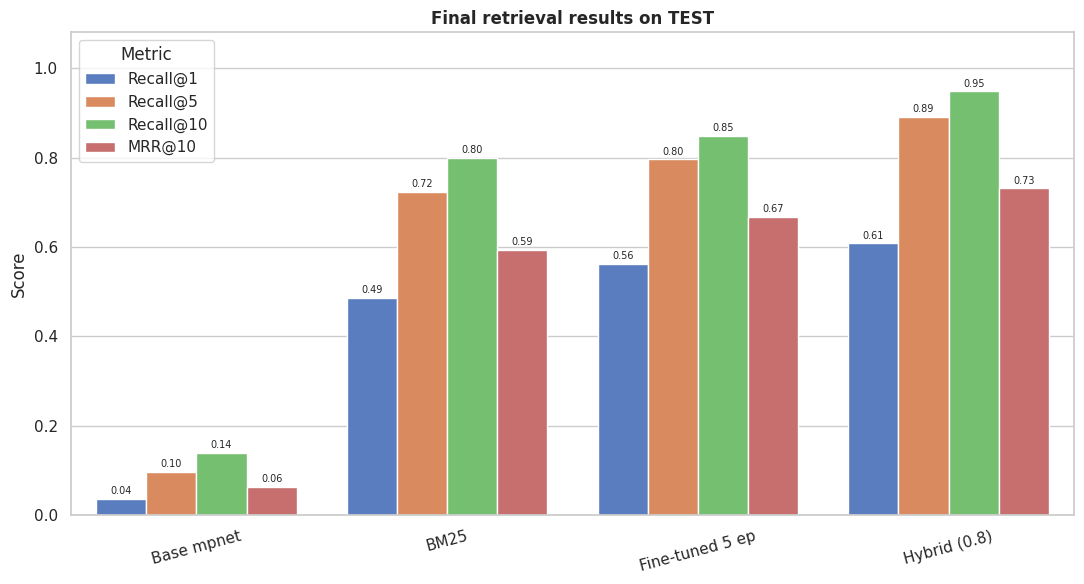

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g2_test_final.png


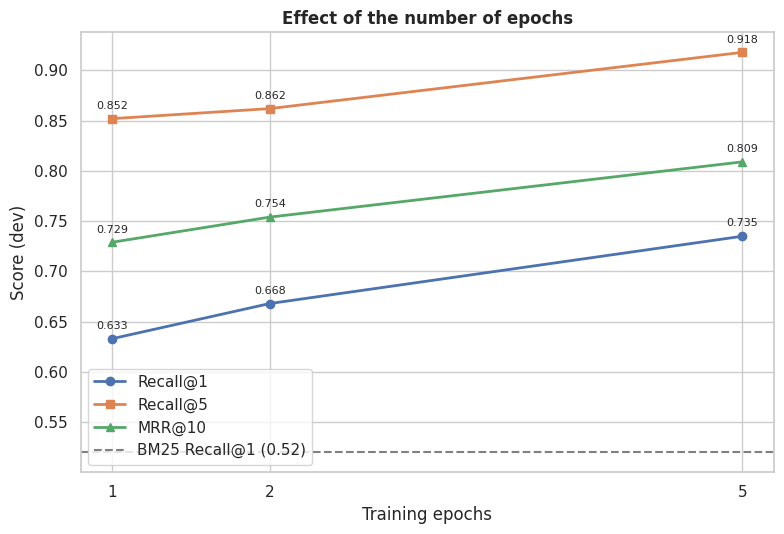

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g3_epochs_effect.png


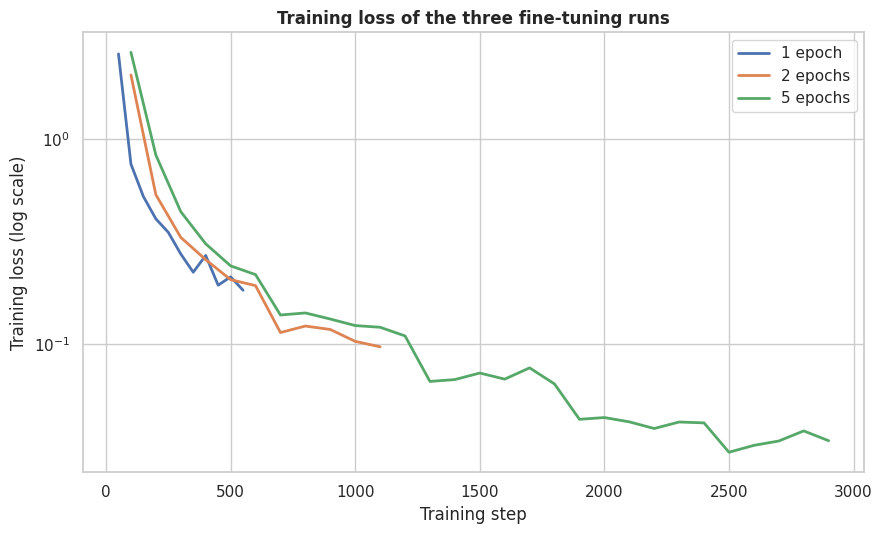

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g4_training_loss.png


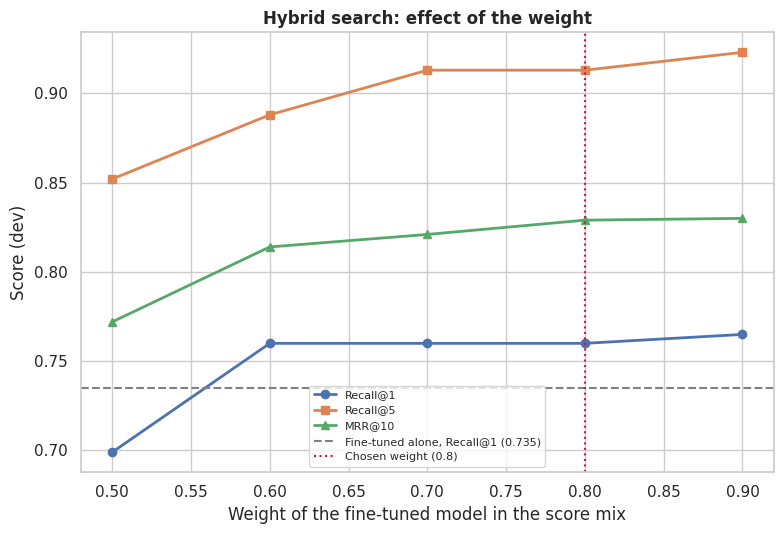

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g5_hybrid_weights.png


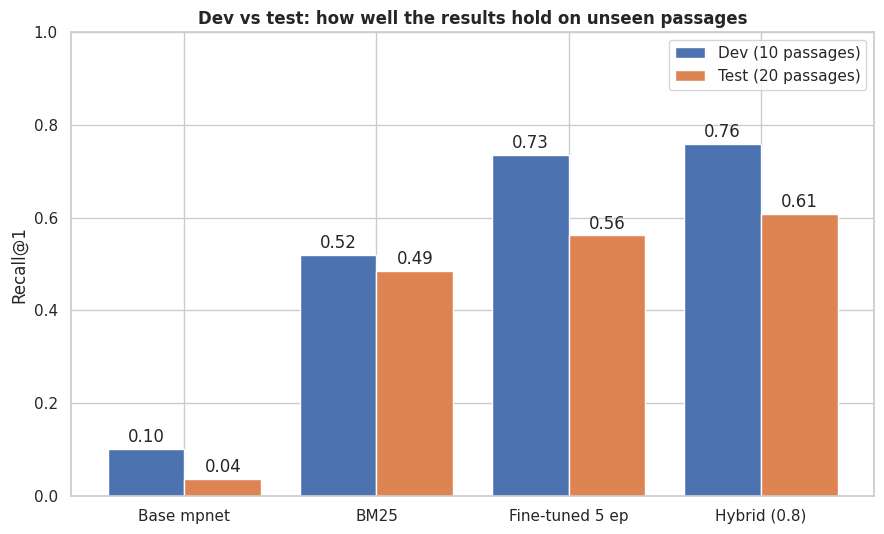

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g6_dev_vs_test.png


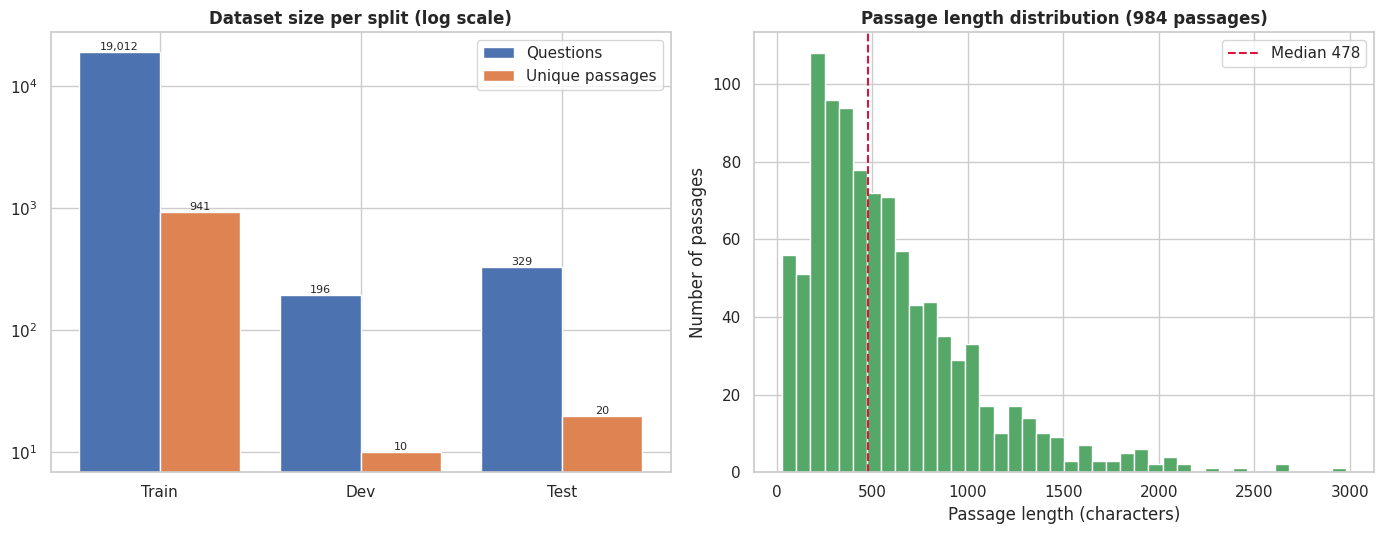

Saved: /content/drive/MyDrive/Mfasha chatbot/data/g7_dataset_overview.png


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd, numpy as np
from pathlib import Path

try:
    SAVE_DIR = Path(RESULTS_DIR)      # laptop
except NameError:
    SAVE_DIR = Path(DATA)             # Colab
sns.set_theme(style="whitegrid")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(SAVE_DIR / name, dpi=300)
    plt.show()
    print("Saved:", SAVE_DIR / name)

M = ["Recall@1", "Recall@5", "Recall@10", "MRR@10"]

# ---------- Your results ----------
dev = pd.DataFrame({
    "Base mpnet":      [0.102, 0.143, 0.148, 0.115],
    "BM25":            [0.520, 0.776, 0.857, 0.627],
    "Fine-tuned 1 ep": [0.633, 0.852, 0.929, 0.729],
    "Fine-tuned 2 ep": [0.668, 0.862, 0.949, 0.754],
    "Fine-tuned 5 ep": [0.735, 0.918, 0.939, 0.809],
    "Hybrid (0.8)":    [0.760, 0.913, 0.949, 0.829],
}, index=M).T

test = pd.DataFrame({
    "Base mpnet":        [0.036, 0.097, 0.140, 0.063],
    "BM25":              [0.486, 0.723, 0.799, 0.594],
    "Fine-tuned 5 ep":   [0.562, 0.796, 0.848, 0.667],
    "Hybrid (0.8)":      [0.608, 0.891, 0.948, 0.731],
}, index=M).T

def grouped_bar(df, title, fname):
    fig, ax = plt.subplots(figsize=(11, 6))
    long = df.reset_index().melt(id_vars="index", var_name="Metric", value_name="Score")
    sns.barplot(data=long, x="index", y="Score", hue="Metric", palette="muted", ax=ax)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(""); ax.set_ylim(0, 1.08)
    ax.tick_params(axis="x", rotation=15)
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, padding=2)
    save(fig, fname)

# 1. Dev: all methods
grouped_bar(dev, "Retrieval results on DEV (all methods)", "g1_dev_all_methods.png")

# 2. Test: final methods
grouped_bar(test, "Final retrieval results on TEST", "g2_test_final.png")

# 3. Effect of epochs
fig, ax = plt.subplots(figsize=(8, 5.5))
ep = [1, 2, 5]
for m, mk in (("Recall@1", "o"), ("Recall@5", "s"), ("MRR@10", "^")):
    ys = [dev.loc[f"Fine-tuned {e} ep", m] for e in ep]
    ax.plot(ep, ys, marker=mk, linewidth=2, label=m)
    for x, y in zip(ep, ys):
        ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.axhline(0.520, color="gray", linestyle="--", label="BM25 Recall@1 (0.52)")
ax.set_xticks(ep); ax.set_xlabel("Training epochs"); ax.set_ylabel("Score (dev)")
ax.set_title("Effect of the number of epochs", fontweight="bold"); ax.legend()
save(fig, "g3_epochs_effect.png")

# 4. Training loss, all three runs
loss1 = ([50,100,150,200,250,300,350,400,450,500,550],
         [2.610915,0.755225,0.524183,0.407939,0.350422,0.274738,0.223771,0.270233,0.193356,0.212299,0.182672])
loss2 = (list(range(100,1200,100)),
         [2.060033,0.535158,0.331195,0.257643,0.205823,0.192400,0.113489,0.122091,0.117469,0.102765,0.096670])
loss5 = (list(range(100,3000,100)),
         [2.657075,0.836309,0.442307,0.308064,0.240322,0.217842,0.138255,0.141495,0.132131,0.122764,
          0.120438,0.109266,0.065475,0.066852,0.071962,0.067182,0.076274,0.063619,0.042749,0.043606,
          0.041542,0.038546,0.041469,0.041059,0.029507,0.031887,0.033489,0.037518,0.033592])
fig, ax = plt.subplots(figsize=(9, 5.5))
for (x, y), lab in ((loss1, "1 epoch"), (loss2, "2 epochs"), (loss5, "5 epochs")):
    ax.plot(x, y, linewidth=2, label=lab)
ax.set_yscale("log"); ax.set_xlabel("Training step"); ax.set_ylabel("Training loss (log scale)")
ax.set_title("Training loss of the three fine-tuning runs", fontweight="bold"); ax.legend()
save(fig, "g4_training_loss.png")

# 5. Hybrid weight sweep on dev
w = [0.5, 0.6, 0.7, 0.8, 0.9]
r1 = [0.699, 0.760, 0.760, 0.760, 0.765]
r5 = [0.852, 0.888, 0.913, 0.913, 0.923]
mrr = [0.772, 0.814, 0.821, 0.829, 0.830]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(w, r1, marker="o", linewidth=2, label="Recall@1")
ax.plot(w, r5, marker="s", linewidth=2, label="Recall@5")
ax.plot(w, mrr, marker="^", linewidth=2, label="MRR@10")
ax.axhline(0.735, color="gray", linestyle="--", label="Fine-tuned alone, Recall@1 (0.735)")
ax.axvline(0.8, color="crimson", linestyle=":", label="Chosen weight (0.8)")
ax.set_xlabel("Weight of the fine-tuned model in the score mix"); ax.set_ylabel("Score (dev)")
ax.set_title("Hybrid search: effect of the weight", fontweight="bold"); ax.legend(fontsize=8)
save(fig, "g5_hybrid_weights.png")

# 6. Dev vs test (generalization gap), Recall@1
names = ["Base mpnet", "BM25", "Fine-tuned 5 ep", "Hybrid (0.8)"]
d1 = [dev.loc[n, "Recall@1"] for n in names]
t1 = [test.loc[n, "Recall@1"] for n in names]
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9, 5.5))
b1 = ax.bar(x - 0.2, d1, 0.4, label="Dev (10 passages)")
b2 = ax.bar(x + 0.2, t1, 0.4, label="Test (20 passages)")
ax.bar_label(b1, fmt="%.2f", padding=2); ax.bar_label(b2, fmt="%.2f", padding=2)
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1); ax.set_ylabel("Recall@1")
ax.set_title("Dev vs test: how well the results hold on unseen passages", fontweight="bold"); ax.legend()
save(fig, "g6_dev_vs_test.png")

# 7. Dataset overview: split sizes + passage length
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
splits = ["Train", "Dev", "Test"]
qs = [19012, 196, 329]; ps = [941, 10, 20]
xx = np.arange(3)
axes[0].bar(xx - 0.2, qs, 0.4, label="Questions", color="#4c72b0")
axes[0].bar(xx + 0.2, ps, 0.4, label="Unique passages", color="#dd8452")
axes[0].set_yscale("log"); axes[0].set_xticks(xx); axes[0].set_xticklabels(splits)
for i, (q, p) in enumerate(zip(qs, ps)):
    axes[0].text(i - 0.2, q, f"{q:,}", ha="center", va="bottom", fontsize=8)
    axes[0].text(i + 0.2, p, f"{p}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("Dataset size per split (log scale)", fontweight="bold"); axes[0].legend()
try:
    lens = [len(t) for t in passage_texts]
    axes[1].hist(lens, bins=40, color="#55a868", edgecolor="white")
    axes[1].axvline(np.median(lens), color="crimson", linestyle="--", label=f"Median {int(np.median(lens))}")
    axes[1].set_xlabel("Passage length (characters)"); axes[1].set_ylabel("Number of passages")
    axes[1].set_title("Passage length distribution (984 passages)", fontweight="bold"); axes[1].legend()
except NameError:
    axes[1].text(0.5, 0.5, "Run the data cell first", ha="center")
save(fig, "g7_dataset_overview.png")